Viewed alexnet.ipynb:1-250
Viewed alexnet.ipynb:250-450
Viewed alexnet.ipynb:1150-1295

`pytorch/chapter_convolutional-modern/alexnet.ipynb`（可点击查看原文件：[alexnet.ipynb](file:///Users/songchao/WorkSpace/Python/DeepLearn/pytorch/chapter_convolutional-modern/alexnet.ipynb)）主要介绍了现代深度学习革命的开山之作 —— **AlexNet**（2012 年 ImageNet 挑战赛冠军模型）。

本章从计算机视觉历史演进、网络架构细节到 PyTorch 代码实现进行了完整讲解，核心内容总结如下：

---

### 一、 历史背景与突破契机

1. **传统视觉 vs 表征学习**：
   * **传统视觉流水线**：依赖手工设计特征（SIFT、SURF、HOG、Bag of Words 等）+ 传统浅层分类器（如 SVM、核方法）。推动领域进展的主要靠特征工程。
   * **深度表征学习**：认为特征应端到端地通过网络参数自主学习，底层学习低级视觉特征（边缘、颜色、纹理），高层组合成局部组件甚至完整物体概念。
2. **突破的两个核心催化因素**：
   * **数据规模**：李飞飞团队构建的 ImageNet 数据集（100 万级图片、1000 个分类），为训练深层大容量网络提供了充足的数据支持。
   * **硬件算力**：GPU（图形处理器）的高并行架构。相比通用复杂设计的 CPU（核数少、单核主频高），GPU 拥有上千个轻量核心及高内存带宽，天然适合密集的矩阵乘法与卷积运算。Alex Krizhevsky 等人编写的 `cuda-convnet` 开启了 GPU 加速深度学习的浪潮。

---

### 二、 AlexNet 核心架构与技术创新（对比 LeNet-5）

| 维度 / 特性 | LeNet-5 | AlexNet | 改进意义 |
| :--- | :--- | :--- | :--- |
| **网络深度** | 2 个卷积层 + 3 个全连接层（共 5 层） | 5 个卷积层 + 3 个全连接层（共 8 层） | 网络更深、感受野更大、表征能力更强 |
| **激活函数** | Sigmoid / Tanh | **ReLU** (`max(0, x)`) | 计算更轻量，正区间导数恒为 1，有效缓解梯度消失，加速模型收敛 |
| **汇聚层方式** | 平均汇聚 / 2×2 非重叠最大汇聚 | **3×3 重叠最大汇聚**（stride=2） | 保留更多空间细节，轻微减弱混叠现象 |
| **容量与正则化**| 主要依靠权重衰减（L2 正则） | 全连接层加入 **Dropout (p=0.5)** + 数据增强 | 强力遏制几千万参数带来的严重过拟合 |
| **输入分辨率** | 28×28 或 32×32 | 224×224 原始自然图像 | 支持高分辨率自然图像分类 |

> **注**：原版 AlexNet 由于当年单块 GPU（NVIDIA GTX 580，显存仅 3GB）容量有限，采用了双卡并行切分通道的设计；当前 PyTorch 教程版本在单 GPU / 统一显存环境下进行了合并与现代化适配。

---

### 三、 网络结构与数据流动（以输入 `(1, 1, 224, 224)` 为例）

```text
输入图像: (1, 1, 224, 224)
  │
  ├─ Conv2d(1 -> 96, k=11, s=4, p=1) + ReLU       --> 输出: (1, 96, 54, 54)
  ├─ MaxPool2d(k=3, s=2)                          --> 输出: (1, 96, 26, 26)
  │
  ├─ Conv2d(96 -> 256, k=5, p=2) + ReLU           --> 输出: (1, 256, 26, 26)
  ├─ MaxPool2d(k=3, s=2)                          --> 输出: (1, 256, 12, 12)
  │
  ├─ Conv2d(256 -> 384, k=3, p=1) + ReLU          --> 输出: (1, 384, 12, 12)
  ├─ Conv2d(384 -> 384, k=3, p=1) + ReLU          --> 输出: (1, 384, 12, 12)
  ├─ Conv2d(384 -> 256, k=3, p=1) + ReLU          --> 输出: (1, 256, 12, 12)
  ├─ MaxPool2d(k=3, s=2)                          --> 输出: (1, 256, 5, 5)
  │
  ├─ Flatten()                                    --> 输出: (1, 6400)  [256 * 5 * 5]
  ├─ Linear(6400 -> 4096) + ReLU + Dropout(0.5)   --> 输出: (1, 4096)
  ├─ Linear(4096 -> 4096) + ReLU + Dropout(0.5)   --> 输出: (1, 4096)
  └─ Linear(4096 -> 10)                           --> 输出: (1, 10)  [适配 Fashion-MNIST 分类]
```

* **计算量分布**：前几层卷积占用最多的计算时间（FLOPs）；
* **参数量分布**：全连接层（尤其是展平后首个 `6400 × 4096` 以及中间的 `4096 × 4096`）占据了模型超过 80%~90% 的参数量与内存空间。

---

### 四、 代码实现与训练关键点

1. **模型定义 (`nn.Sequential`)**：
   使用 PyTorch 的 `nn.Conv2d`、`nn.MaxPool2d`、`nn.Dropout` 与 `nn.Linear` 搭建前向序列。
2. **数据集调整与预处理**：
   由于完整训练 ImageNet 成本过高，笔记本中使用 Fashion-MNIST（单通道，原始尺寸 28×28），通过 `d2l.load_data_fashion_mnist(batch_size=128, resize=224)` 将图片双线性插值放大至 `224×224` 以适配 AlexNet 结构。
3. **训练参数配置**：
   * 学习率设为 `lr = 0.01`（相比 LeNet-5 使用了更小的学习率以确保深层网络收敛稳定）；
   * 训练轮数 `num_epochs = 10`，在 GPU 环境下 10 轮后测试集准确率可达到约 **88%** 左右。

---

### 五、 核心总结与启示

* **里程碑地位**：AlexNet 是从浅层手绘特征过渡到深度自动特征学习的分水岭，证明了端到端深层卷积网络的实用价值。
* **现代 CNN 标配三件套**：**ReLU**（防梯度消失）、**Dropout**（全连接层控过拟合）、**数据增强**（扩大有效样本空间）成为后续现代 CNN 设计的标准范式。

In [1]:
import torch
from torch import nn
from d2l import torch as d2l

In [2]:
from torchgen.api.ufunc import kernel_name
net = nn.Sequential(
    nn.Conv2d(1, 96, kernel_size=11, stride=4, padding=1), nn.ReLU(),
    nn.MaxPool2d(kernel_size=3, stride=2),
    nn.Conv2d(96, 256, kernel_size=5, padding=2), nn.ReLU(),
    nn.MaxPool2d(kernel_size=3, stride=2),
    nn.Conv2d(256, 384, kernel_size=3, padding=1), nn.ReLU(),
    nn.Conv2d(384, 384, kernel_size=3, padding=1), nn.ReLU(),
    nn.Conv2d(384, 256, kernel_size=3, padding=1), nn.ReLU(),
    nn.MaxPool2d(kernel_size=3, stride=2),
    nn.Flatten(),
    nn.Linear(6400, 4096), nn.ReLU(),
    nn.Dropout(0.5),
    nn.Linear(4096, 4096), nn.ReLU(),
    nn.Dropout(0.5),
    nn.Linear(4096, 10)
)

In [5]:
X = torch.rand(size=(1,1,224,224))
for layer in net:
    X = layer(X)
    print(layer.__class__.__name__, 'output shape:\t', X.shape)

Conv2d output shape:	 torch.Size([1, 96, 54, 54])
ReLU output shape:	 torch.Size([1, 96, 54, 54])
MaxPool2d output shape:	 torch.Size([1, 96, 26, 26])
Conv2d output shape:	 torch.Size([1, 256, 26, 26])
ReLU output shape:	 torch.Size([1, 256, 26, 26])
MaxPool2d output shape:	 torch.Size([1, 256, 12, 12])
Conv2d output shape:	 torch.Size([1, 384, 12, 12])
ReLU output shape:	 torch.Size([1, 384, 12, 12])
Conv2d output shape:	 torch.Size([1, 384, 12, 12])
ReLU output shape:	 torch.Size([1, 384, 12, 12])
Conv2d output shape:	 torch.Size([1, 256, 12, 12])
ReLU output shape:	 torch.Size([1, 256, 12, 12])
MaxPool2d output shape:	 torch.Size([1, 256, 5, 5])
Flatten output shape:	 torch.Size([1, 6400])
Linear output shape:	 torch.Size([1, 4096])
ReLU output shape:	 torch.Size([1, 4096])
Dropout output shape:	 torch.Size([1, 4096])
Linear output shape:	 torch.Size([1, 4096])
ReLU output shape:	 torch.Size([1, 4096])
Dropout output shape:	 torch.Size([1, 4096])
Linear output shape:	 torch.Size([1,

In [6]:
batch_size = 128
train_iter, test_iter = d2l.load_data_fashion_mnist(batch_size, resize=224)

loss 0.329, train acc 0.879, test acc 0.880
31.2 examples/sec on cpu


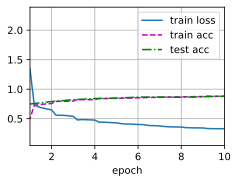

In [7]:
lr, num_epochs = 0.01, 10
d2l.train_ch6(net, train_iter, test_iter, num_epochs, lr, device=d2l.try_gpu())

以下是针对 [alexnet.ipynb](file:///Users/songchao/WorkSpace/Python/DeepLearn/pytorch/chapter_convolutional-modern/alexnet.ipynb) 课后练习题的详细分析与解答：

---

### 1. 试着增加迭代轮数。对比 LeNet 的结果有什么不同？为什么？

* **收敛行为差异**：
  * **LeNet-5**：模型参数量较小（约 6 万），在 10~15 轮左右精度就会基本饱和。继续增加轮数，由于模型容量有限，准确率难以再有明显突破，但一般也不会出现极端的过拟合。
  * **AlexNet**：模型容量大（约数千万参数），表征能力极强。在增加迭代轮数（如增至 20~30 轮）后，训练集准确率会继续攀升（逼近 95%+），但测试集准确率往往在 88%~90% 附近滞涨甚至出现轻微回落，开始出现过拟合迹象。
* **原因分析**：
  1. **数据与容量不匹配**：Fashion-MNIST 图像较简单，本教程中强行插值放大到 `224×224` 会引入大量平滑伪影，对 AlexNet 这样庞大的模型来说数据集信息量不足，长时间训练容易使模型记住训练样本中的特定噪声。
  2. **训练时间成本**：AlexNet 的单轮浮点计算量是 LeNet 的上百倍，增加迭代轮数带来的时间与算力开销远高于 LeNet。

---

### 2. AlexNet 对 Fashion-MNIST 数据集来说可能太复杂了

#### (1) 尝试简化模型以加快训练速度，同时确保准确性不会显著下降
* **瘦身思路**：
  1. **精简全连接层**：AlexNet 中两个全连接层的隐藏维度是 4096，占用了 80% 以上的参数量。将其降至 `512` 或 `1024`（如 `Linear(6400, 512)`），参数量立减近一个数量级，前向反向速度大幅提升，而在该任务上准确率几乎不下降。
  2. **缩减卷积通道数**：将各卷积层通道数减半（如 96/256/384 缩减为 48/128/192），可大幅减少卷积 FLOPs 与显存占用。
  3. **精简卷积层数**：去掉后部 1~2 个 `3×3` 卷积层。

#### (2) 设计一个可以直接在 `28×28` 图像上工作的模型
* **面临的问题**：原版 AlexNet 第一层卷积核为 `11×11`、步幅为 4，若输入只有 `28×28`，一次卷积后特征图尺寸仅剩 `(28 - 11 + 2)/4 + 1 = 5`，无法再接后续的多层池化与多层卷积。
* **架构设计方案**：
  * 将第 1 层卷积核缩小为 `3×3`（步幅 1，padding=1），避免空间分辨率过早塌缩；
  * 池化层改为标准的 `kernel_size=2, stride=2`；
  * 减少中间卷积层数，并使用更紧凑的全连接隐藏层。
* **PyTorch 示例实现**：
```python
import torch
from torch import nn

alexnet_small = nn.Sequential(
    # 保持 28*28 分辨率缓慢降采样
    nn.Conv2d(1, 32, kernel_size=3, padding=1), nn.ReLU(),
    nn.MaxPool2d(kernel_size=2, stride=2),  # 28 -> 14
    nn.Conv2d(32, 64, kernel_size=3, padding=1), nn.ReLU(),
    nn.MaxPool2d(kernel_size=2, stride=2),  # 14 -> 7
    nn.Conv2d(64, 128, kernel_size=3, padding=1), nn.ReLU(),
    nn.MaxPool2d(kernel_size=2, stride=2),  # 7 -> 3
    nn.Flatten(),                           # 128 * 3 * 3 = 1152
    nn.Linear(1152, 256), nn.ReLU(),
    nn.Dropout(0.5),
    nn.Linear(256, 10)
)
```
> 该模型无需对原图进行 `resize=224` 插值，显存和计算耗时只有原先的数十分之一，且能达到甚至超越原版适配在 Fashion-MNIST 上的分类精度。

---

### 3. 修改批量大小，并观察模型精度和 GPU 显存变化

* **GPU 显存（VRAM）变化**：
  * 显存占用主要由「模型静态参数」和「动态激活值（Feature Maps）+ 梯度」构成。
  * 中间层激活值的内存开销与批量大小 `batch_size` 严格成正比。若将 `batch_size` 从 64 增加到 256 或 512，激活值张量成倍增加，显存占用显著上升；设置过大时会触发 CUDA Out-Of-Memory (OOM)。
* **模型精度与训练动态**：
  * **过大的 Batch**（如 512+）：梯度方差减小，方向过于平滑，容易收敛到较陡峭的局部极小值点，降低模型泛化能力；若未按比例提高学习率（Linear Scaling Rule），收敛速度会变慢。
  * **适中的 Batch**（如 64 ~ 128）：梯度带有适度噪声，有助于跳出不良鞍点和局部最优点，泛化表现最好。
  * **过小的 Batch**（如 16）：梯度噪声太大，震荡剧烈，GPU 算力利用率低下（无法发挥 Tensor Core / 并行单元高吞吐）。

---

### 4. 分析 AlexNet 的计算性能

#### (1) 在 AlexNet 中主要是哪部分占用显存？
* **模型参数显存**：主要被**全连接层**占据。展平后的 `6400 × 4096` 和 `4096 × 4096` 两个全连接矩阵包含数千万浮点数，模型权重、偏置及 Adam/SGD 动量缓存基本都集中在此处。
* **运行时激活值显存**：主要被**浅层卷积层**占据。因为第 1、2 层卷积输出的特征图尺寸较大（例如第一层特征图为 `96 × 54 × 54`），在前向传播保存用于反向传播求导时，需占用大量显存。

#### (2) 在 AlexNet 中主要是哪部分需要更多的计算？
* **卷积层**占据了 90% 以上的计算量（FLOPs）。每个卷积核都需要在全图像空间滑窗进行多通道乘加累加，前两层和第三层卷积的浮点运算次数极为庞大；而全连接层虽然权重多，但仅是一次矩阵乘法，计算量远少于卷积层。

#### (3) 计算结果时显存带宽如何？
* **全连接层（Memory-Bound，访存密集）**：运算强度（FLOP/Byte）较低。每个庞大的权重在一次前向传播中仅与一个特征相乘，导致大量的显存读取换来较少的计算，瓶颈在于 GPU 的显存带宽传输速度。
* **卷积层（Compute-Bound，计算密集）**：运算强度较高。由于权值共享（Weight Sharing），同一个卷积核被读入寄存器/缓存后在整张特征图上反复滑动复用，更充分地利用了 GPU 核心的算力。
* **池化与 ReLU 层**：仅涉及简单的取最大值或阈值截断，几乎不需要乘法计算，完全属于纯显存带宽吞吐瓶颈。

---

### 5. 将 Dropout 和 ReLU 应用于 LeNet-5，效果有提升吗？再试试预处理会怎么样？

1. **引入 ReLU**：
   * **提升显著**。原版 LeNet-5 使用 Sigmoid/Tanh，激活区两端饱和容易引发梯度弥散。换为 `ReLU` 后计算开销更低，且正区间导数恒为 1，网络收敛速度显著加快，最终分类准确率通常有 1%~3% 的稳定提升。
2. **引入 Dropout**：
   * **需谨慎调节**。LeNet 本身体积小、参数量少（卷积层不易过拟合），如果在最后两层全连接加入较小丢弃率的 Dropout（如 `p = 0.2 ~ 0.3`），能轻微改善测试集泛化；但若直接使用 `p = 0.5`，可能会因为模型容量本就不大而导致欠拟合，使性能反而下降。
3. **数据预处理与增强**：
   * **数据标准化（Standardization）**：将输入均值调至 0、方差调至 1，使得梯度下降方向更均衡，加速收敛。
   * **轻量级数据增强**（随机微小旋转、随机裁剪和平移）：有效增加训练样本分布多样性，可以防止 LeNet 在 Fashion-MNIST 上的微弱过拟合，使测试集泛化精度进一步提升。